# Pair 4 — Image generation comparison

**Models:** Z-Image-Turbo (SDNQ 4-bit) and FLUX.2 klein 4B (SDNQ)

I tested both models on the same 30 Amazon product advertising prompts, with 512 × 512 outputs and matching seed identifiers. This notebook compares **(1) all outputs side by side**, **(2) generation speed**, and **(3) a qualitative scoring rubric**. It uses previously generated images and timing records; it does not run either model again.

In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw, ImageFont
from IPython.display import display

HERE = Path.cwd().resolve()
if (HERE / "prompts.csv").exists():
    BASE = HERE
elif (HERE / "Models" / "Pair_04" / "prompts.csv").exists():
    BASE = HERE / "Models" / "Pair_04"
else:
    raise FileNotFoundError("Run from your repository root.")

OUT = BASE / "results" / "Comparison"
OUT.mkdir(parents=True, exist_ok=True)

MODEL_DIRS = {
    "Z-Image-Turbo": BASE / "results" / "Z_Image_Turbo",
    "FLUX.2 klein": BASE / "results" / "FLUX2_Klein",
}

prompts = pd.read_csv(BASE / "prompts.csv")
assert "prompt" in prompts.columns and "prompt_id" in prompts.columns
assert len(prompts) == 30 and prompts.prompt_id.is_unique
prompts["prompt_id"] = prompts["prompt_id"].astype(str)

results, summaries = {}, {}
for model, directory in MODEL_DIRS.items():
    results[model] = pd.read_csv(directory / "generation_results.csv")
    results[model]["prompt_id"] = results[model]["prompt_id"].astype(str)
    with open(directory / "summary.json", encoding="utf-8") as f:
        summaries[model] = json.load(f)
    assert set(results[model].prompt_id) == set(prompts.prompt_id), f"Missing prompt IDs for {model}"
    if "prompt" in results[model]:
        observed = results[model].set_index("prompt_id")["prompt"]
        expected = prompts.set_index("prompt_id")["prompt"]
        assert observed.loc[expected.index].equals(expected), f"Prompt text changed for {model}"

print("Pair 4 folder:", BASE)
print("Prompts:", len(prompts))
print("Comparison outputs:", OUT)

Pair 4 folder: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04
Prompts: 30
Comparison outputs: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04\results\Comparison


## 1. Side-by-side overview of all 30 products

Each numbered pair uses the same prompt: Z-Image-Turbo on the left and FLUX.2 klein on the right. I arranged three product pairs per row, giving a 10-row high-resolution overview of all 60 images. The numbered labels match `prompts.csv`. A copy is saved as `results/Comparison/paired_overview.png` for my report or presentation.

Overview: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04\results\Comparison\paired_overview.png
Size: (3174, 6043)


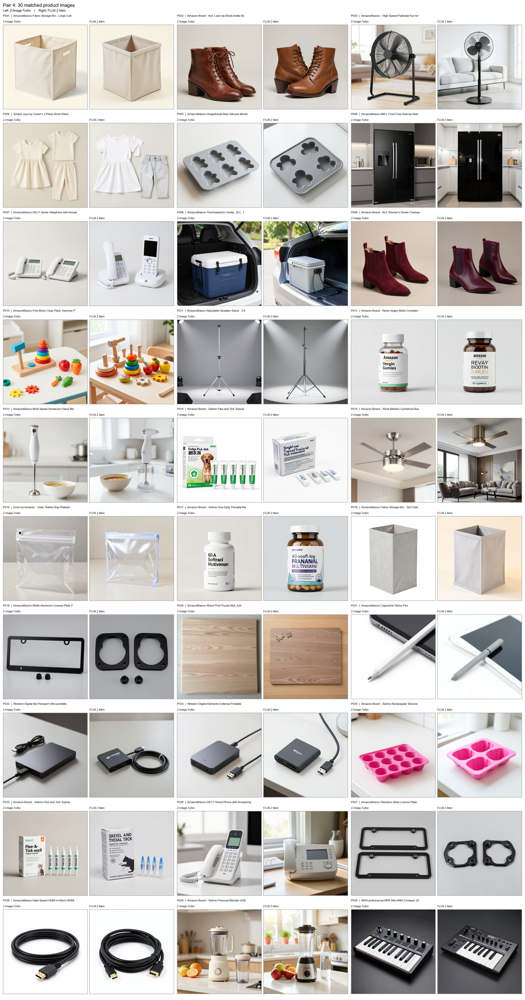

In [4]:
def font(size):
    for path in [
        "C:/Windows/Fonts/arial.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    ]:
        if Path(path).exists():
            return ImageFont.truetype(path, size)
    return ImageFont.load_default()


def image_for(model, prompt_id):
    table = results[model].set_index("prompt_id")
    row = table.loc[prompt_id]
    if row["status"] != "success":
        return None
    path = MODEL_DIRS[model] / "images" / f"{prompt_id}.png"
    # Images are saved by prompt ID in both generation notebooks.
    return path if path.exists() else None


def paired_sheet(thumb=512, pairs_per_row=3):
    gutter = 18
    top = 85
    row_heading = 36
    label_h = 28
    pair_w = 2 * thumb + 10
    block_w = pair_w + gutter
    nrows = int(np.ceil(len(prompts) / pairs_per_row))
    block_h = row_heading + label_h + thumb + gutter
    width = gutter + pairs_per_row * block_w
    height = top + nrows * block_h + gutter
    canvas = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(canvas)
    draw.text((gutter, 15), "Pair 4: 30 matched product images", fill="black", font=font(28))
    draw.text((gutter, 52), "Left: Z-Image-Turbo    |    Right: FLUX.2 klein", fill="black", font=font(19))
    missing = []
    for i, row in prompts.reset_index(drop=True).iterrows():
        r, c = divmod(i, pairs_per_row)
        x = gutter + c * block_w
        y = top + r * block_h
        draw.text((x, y), f"{row.prompt_id}  |  {str(row.get('product_name', row.get('item_id', '')))[:43]}",
                  fill="black", font=font(17))
        for j, model in enumerate(MODEL_DIRS):
            px = x + j * (thumb + 10)
            py = y + row_heading + label_h
            draw.text((px, y + row_heading), model, fill="black", font=font(16))
            path = image_for(model, row.prompt_id)
            if path is not None:
                with Image.open(path) as src:
                    tile = ImageOps.pad(src.convert("RGB"), (thumb, thumb), method=Image.Resampling.LANCZOS, color="white")
                canvas.paste(tile, (px, py))
            else:
                missing.append((row.prompt_id, model))
                draw.rectangle((px, py, px + thumb, py + thumb), outline="#888888", width=2)
                draw.text((px+25,py+25), "IMAGE MISSING", fill="red", font=font(22))
            draw.rectangle((px, py, px+thumb-1, py+thumb-1), outline="#999999", width=2)
    dest = OUT / "paired_overview.png"
    canvas.save(dest, optimize=True)
    return dest, canvas, missing

sheet_path, overview, missing = paired_sheet(thumb=512, pairs_per_row=3)
print("Overview:", sheet_path)
print("Size:", overview.size)
if missing:
    print("Missing images:", missing)
# Notebook preview is scaled for screen; saved PNG retains its full resolution.
display(overview.resize((min(1500, overview.width), int(overview.height * min(1500, overview.width) / overview.width))))

## 2. Generation speed and reliability

I measured wall-clock image-generation time with CUDA synchronisation, excluding initial model loading. The comparison uses each model's recorded recommended inference configuration, so the timings are **not** a same-step computational benchmark.

In [5]:
rows = []
for model in MODEL_DIRS:
    s = summaries[model]
    rows.append({
        "Model": model,
        "Successful": s["successful_images"],
        "Failed": s["failed_images"],
        "Mean seconds": s["mean_generation_seconds"],
        "Median seconds": s["median_generation_seconds"],
        "Steps": s["steps"],
        "Guidance": s["guidance_scale"],
        "Resolution": f'{s["width"]} × {s["height"]}',
    })
speed_summary = pd.DataFrame(rows).set_index("Model")
display(speed_summary.round(2))
speed_summary.to_csv(OUT / "speed_summary.csv")

zmean = speed_summary.loc["Z-Image-Turbo", "Mean seconds"]
fmean = speed_summary.loc["FLUX.2 klein", "Mean seconds"]
print(f"Z-Image-Turbo / FLUX.2 klein mean time ratio: {zmean/fmean:.2f}×")

,Successful,Failed,Mean seconds,Median seconds,Steps,Guidance,Resolution
Model,,,,,,,
Z-Image-Turbo,30,0,10.97,10.68,9,0.0,512 × 512
FLUX.2 klein,30,0,4.84,4.53,4,1.0,512 × 512


Z-Image-Turbo / FLUX.2 klein mean time ratio: 2.27×


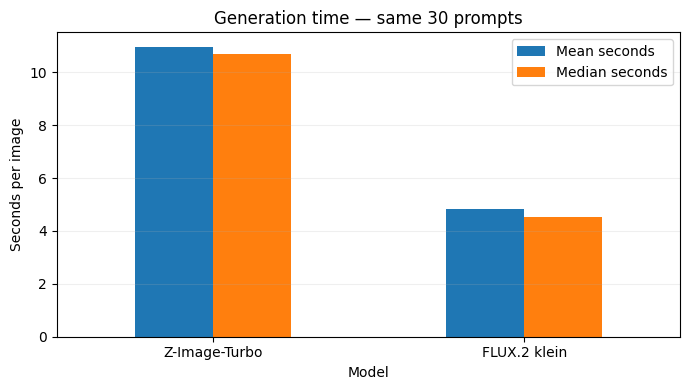

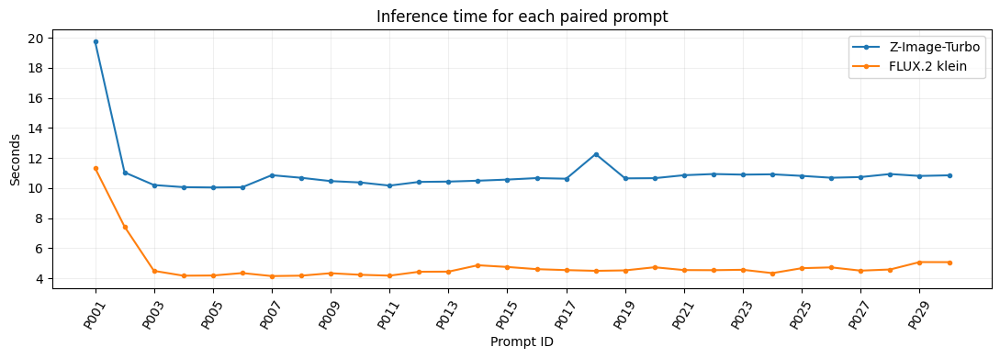

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
speed_summary[["Mean seconds", "Median seconds"]].plot.bar(ax=ax, rot=0)
ax.set_ylabel("Seconds per image")
ax.set_title("Generation time — same 30 prompts")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "speed_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

# Pair the per-prompt timings to show differences beyond overall averages.
a = results["Z-Image-Turbo"][["prompt_id", "generation_seconds", "status"]].rename(
    columns={"generation_seconds": "Z_seconds", "status": "Z_status"})
b = results["FLUX.2 klein"][["prompt_id", "generation_seconds", "status"]].rename(
    columns={"generation_seconds": "FLUX_seconds", "status": "FLUX_status"})
times = prompts[["prompt_id"]].merge(a, on="prompt_id").merge(b, on="prompt_id")
times.to_csv(OUT / "paired_generation_times.csv", index=False)
valid = times[(times.Z_status == "success") & (times.FLUX_status == "success")].copy()
valid["Z_seconds"] = pd.to_numeric(valid.Z_seconds)
valid["FLUX_seconds"] = pd.to_numeric(valid.FLUX_seconds)
fig, ax = plt.subplots(figsize=(11, 4))
positions = np.arange(len(valid))
ax.plot(positions, valid.Z_seconds, marker="o", markersize=3, label="Z-Image-Turbo")
ax.plot(positions, valid.FLUX_seconds, marker="o", markersize=3, label="FLUX.2 klein")
ax.set_xticks(positions[::2], valid.prompt_id.iloc[::2], rotation=60)
ax.set_ylabel("Seconds")
ax.set_xlabel("Prompt ID")
ax.set_title("Inference time for each paired prompt")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "time_by_prompt.png", dpi=220, bbox_inches="tight")
plt.show()

## 3. Qualitative evaluation rubric

I use the same four criteria and 1–5 scale for both models. I score images individually using the original prompt and the full-resolution PNG, rather than deciding only from the contact sheet.

| Criterion | What I check |
|---|---|
| **Prompt adherence** | Does the image include the product, attributes, quantity, and requested composition? |
| **Visual quality** | Are lighting, realism, sharpness, and product geometry convincing? |
| **Product accuracy** | Are the product's important parts, labels, colour and physical structure correct? |
| **Advertising suitability** | Could Amazon use this image with minimal corrections, without misleading customers? |

**Scale:** 1 = very poor, 2 = poor, 3 = acceptable, 4 = good, 5 = excellent. Scored only what is visible, and check uncertain details against the prompt. Because this is a single-rater study, subjective judgements are a limitation.

I created `manual_scores.csv` with 60 rows. Filled the four numeric columns (1–5). The sheet uses the original model names for convenience; for a less biased review I can hide these columns while scoring.

In [7]:
SCORE_FILE = OUT / "manual_scores.csv"

scores = pd.read_csv(SCORE_FILE)
display(scores.head(6))

,prompt_id,item_id,model,image_path,prompt_adherence,visual_quality,product_accuracy,advertising_suitability,rating_source
0,P001,B07QFRCVFD,Z-Image-Turbo,results/Z_Image_Turbo/images/P001.png,5,5,4,5,User reviewed
1,P001,B07QFRCVFD,FLUX.2 klein,results/FLUX2_Klein/images/P001.png,5,5,4,5,User reviewed
2,P002,B07R79WQZB,Z-Image-Turbo,results/Z_Image_Turbo/images/P002.png,5,5,5,5,User reviewed
3,P002,B07R79WQZB,FLUX.2 klein,results/FLUX2_Klein/images/P002.png,5,5,5,5,User reviewed
4,P003,B07NP6BV1H,Z-Image-Turbo,results/Z_Image_Turbo/images/P003.png,2,5,2,2,User reviewed
5,P003,B07NP6BV1H,FLUX.2 klein,results/FLUX2_Klein/images/P003.png,5,4,5,5,User reviewed


### Qualitative Examples

To examine the differences between the two models, I selected three examples based on their average qualitative scores: the largest scoring difference, the lowest-scoring pair, and the highest-scoring pair.

The images are displayed side by side with their product names and scores. This helps identify where the models perform well, where they struggle, and which model better follows the product description.

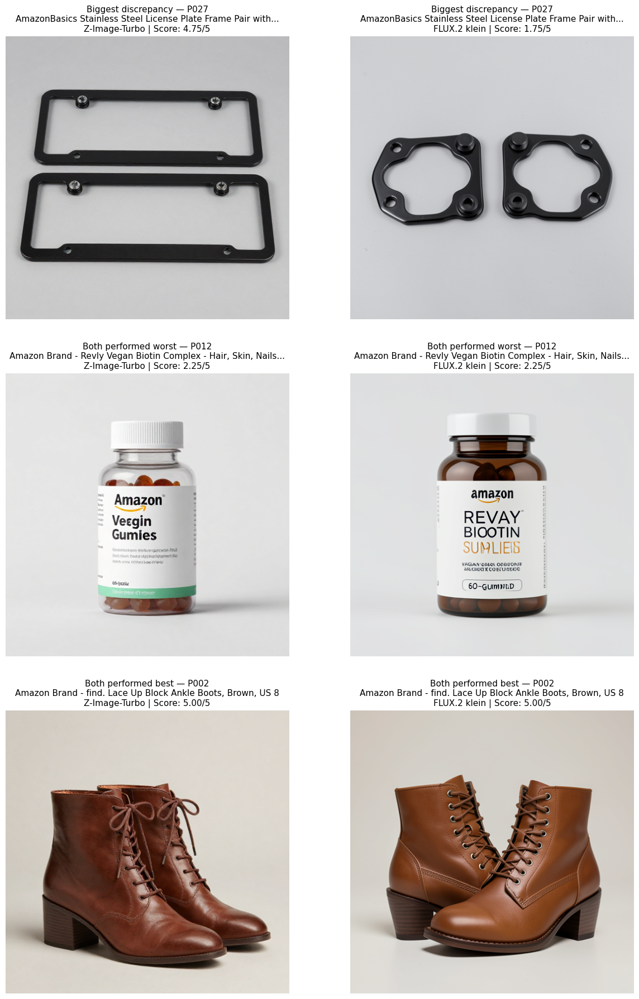


Biggest discrepancy — P027
Product: AmazonBasics Stainless Steel License Plate Frame Pair with Screw Caps - 4-Hole, 12.2″ x 6.3″, Black
Prompt: Crisp automotive product photograph of a pair of black stainless-steel four-hole licence-plate frames with their matching screw caps. Lay the two frames neatly on a light grey studio surface to show all four mounting holes, realistic metallic edges, uniform lighting and no licence plate numbers.
Z-Image-Turbo: 4.75/5
FLUX.2 klein: 1.75/5
--------------------------------------------------------------------------------

Both performed worst — P012
Product: Amazon Brand - Revly Vegan Biotin Complex - Hair, Skin, Nails - 60 Gummies (2,500 mcg Biotin per serving, with Vitamin C & E), Gluten Free, Non-GMO
Prompt: Clean ecommerce product photo of an Amazon Revly vegan biotin gummies supplement bottle labelled as a 60-gummy product. Display a single sealed bottle on a plain light background with soft studio lighting. Focus on believable bottle and cap

In [8]:
import textwrap

scores = pd.read_csv(OUT / "manual_scores.csv")

criteria = [
    "prompt_adherence",
    "visual_quality",
    "product_accuracy",
    "advertising_suitability"
]

scores = scores.dropna(subset=criteria).copy()
scores["overall_score"] = scores[criteria].mean(axis=1)

paired = scores.pivot(
    index="prompt_id",
    columns="model",
    values="overall_score"
).dropna()

z = "Z-Image-Turbo"
f = "FLUX.2 klein"

# Select the three examples
biggest_gap = (paired[z] - paired[f]).abs().idxmax()
both_failed = paired[[z, f]].max(axis=1).idxmin()
both_best = paired[[z, f]].min(axis=1).idxmax()

examples = [
    ("Biggest discrepancy", biggest_gap),
    ("Both performed worst", both_failed),
    ("Both performed best", both_best)
]

# Get product names and prompts
product_info = prompts.set_index("prompt_id")

fig, axes = plt.subplots(3, 2, figsize=(13, 18))

for row, (label, prompt_id) in enumerate(examples):
    product_name = product_info.loc[prompt_id, "product_name"]

    # Wrap long product names
    short_name = textwrap.shorten(
        str(product_name), width=65, placeholder="..."
    )

    for col, model in enumerate([z, f]):
        path = image_for(model, prompt_id)

        if path is not None:
            img = Image.open(path).convert("RGB")
            axes[row, col].imshow(img)

        score = paired.loc[prompt_id, model]

        axes[row, col].set_title(
            f"{label} — {prompt_id}\n"
            f"{short_name}\n"
            f"{model} | Score: {score:.2f}/5",
            fontsize=11
        )
        axes[row, col].axis("off")

plt.tight_layout(h_pad=3)

plt.savefig(
    OUT / "qualitative_examples.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Print product names, full prompts and scores
for label, prompt_id in examples:
    product = product_info.loc[prompt_id]

    print(f"\n{label} — {prompt_id}")
    print(f"Product: {product['product_name']}")
    print(f"Prompt: {product['prompt']}")
    print(f"Z-Image-Turbo: {paired.loc[prompt_id, z]:.2f}/5")
    print(f"FLUX.2 klein: {paired.loc[prompt_id, f]:.2f}/5")
    print("-" * 80)

,prompt_adherence,visual_quality,product_accuracy,advertising_suitability,overall_score
model,,,,,
FLUX.2 klein,3.400,4.400,3.167,3.233,3.550
Z-Image-Turbo,3.667,4.433,3.467,3.500,3.767


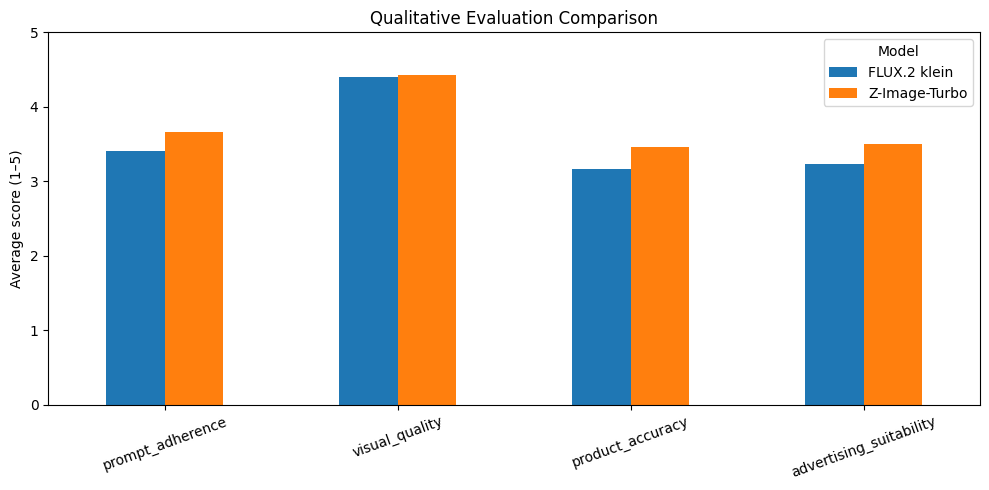

Products evaluated: 30
Best model for image quality: Z-Image-Turbo
Average score difference: 0.217/5


In [10]:
# Compare qualitative scores between both models
scores = pd.read_csv(OUT / "manual_scores.csv")

criteria = [
    "prompt_adherence",
    "visual_quality",
    "product_accuracy",
    "advertising_suitability"
]

scores[criteria] = scores[criteria].apply(pd.to_numeric, errors="coerce")
scores = scores.dropna(subset=criteria).copy()

# Calculate overall score for each image
scores["overall_score"] = scores[criteria].mean(axis=1)

# Keep only prompts evaluated for both models
paired = scores.pivot_table(
    index="prompt_id",
    columns="model",
    values="overall_score"
).dropna()

scores = scores[scores["prompt_id"].isin(paired.index)]

# Calculate average scores
comparison = scores.groupby("model")[
    criteria + ["overall_score"]
].mean()

display(comparison.round(3))

# Plot qualitative score comparison
ax = comparison[criteria].T.plot.bar(
    figsize=(10, 5),
    rot=20
)

ax.set_title("Qualitative Evaluation Comparison")
ax.set_ylabel("Average score (1–5)")
ax.set_ylim(0, 5)
ax.legend(title="Model")
plt.tight_layout()
plt.savefig(OUT / "qualitative_comparison.png", dpi=200)
plt.show()

# Compare overall quality
winner = comparison["overall_score"].idxmax()
difference = (
    comparison["overall_score"].max()
    - comparison["overall_score"].min()
)

print(f"Products evaluated: {len(paired)}")
print(f"Best model for image quality: {winner}")
print(f"Average score difference: {difference:.3f}/5")


# Save results
comparison.to_csv(OUT / "qualitative_comparison.csv")

### Final Evaluation and Recommendation

After manually evaluating all 60 generated images, Z-Image-Turbo achieved a higher overall qualitative score of 3.767/5 compared with FLUX.2 klein's 3.550/5. Z-Image-Turbo performed better across all four evaluation criteria, with the largest improvements in product accuracy and prompt adherence. However, both models achieved similar visual quality scores.

The qualitative examples highlight these differences. For P027, Z-Image-Turbo generated a more accurate representation of the licence-plate frames, while FLUX.2 klein struggled with the requested product structure. Both models performed poorly on P012, the biotin gummies, showing difficulties with product packaging. In contrast, both achieved perfect scores for P002, the brown ankle boots.

FLUX.2 klein had a significant efficiency advantage, generating images approximately 2.27 times faster than Z-Image-Turbo. Therefore, FLUX.2 klein may be preferable when generating a large number of initial advertising concepts.

For Amazon, I would recommend Z-Image-Turbo when product accuracy and adherence to the description are more important than generation speed. However, neither model should be used to publish product advertisements without human verification, as both occasionally generated incorrect product features.

These findings are based on 30 prompts and ratings from one evaluator. Further testing with additional products, seeds and independent evaluators would improve the reliability of the comparison.